In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df=pd.read_csv('pg_food_waste_200_people.csv')
print(df.head())
print(df.columns)
print(df.shape)

  Student_ID        Date       Meal        Food_Item  Food_Served_g  \
0      PG121  2026-10-01  Breakfast             Poha            294   
1      PG145  2026-10-01      Lunch        Curd Rice            372   
2      PG055  2026-10-02     Dinner  Vegetable Curry            281   
3      PG056  2026-10-02     Dinner          Khichdi            262   
4      PG072  2026-10-02     Dinner  Vegetable Curry            300   

   Food_Consumed_g  Food_Waste_g  
0              236            58  
1              291            81  
2              212            69  
3              199            63  
4              290            10  
Index(['Student_ID', 'Date', 'Meal', 'Food_Item', 'Food_Served_g',
       'Food_Consumed_g', 'Food_Waste_g'],
      dtype='object')
(200, 7)


In [18]:
import numpy as np

print("Total Served:", df['Food_Served_g'].sum(), "g")
print("Total Waste:", df['Food_Waste_g'].sum(), "g")
print("Average Waste:", round(np.mean(df['Food_Waste_g']), 2), "g")
print("Average Waste %:", round(np.mean(df['Waste_Percent']), 2), "%")

print("\n--- Meal Wise Waste ---")
print(df.groupby('Meal')['Food_Waste_g'].mean())

print("\n--- Food Item Wise Waste ---")
print(df.groupby('Food_Item')['Food_Waste_g'].mean().sort_values(ascending=False))

Total Served: 68604 g
Total Waste: 11895 g
Average Waste: 59.48 g
Average Waste %: 17.54 %

--- Meal Wise Waste ---
Meal
Breakfast    57.697368
Dinner       60.850746
Lunch        60.228070
Name: Food_Waste_g, dtype: float64

--- Food Item Wise Waste ---
Food_Item
Rice               82.588235
Pongal             76.272727
Dosa               68.000000
Sambar             61.555556
Khichdi            59.947368
Chapati            58.888889
Curd Rice          58.062500
Dal                57.250000
Upma               52.133333
Vegetable Curry    51.961538
Poha               49.894737
Idli               38.800000
Name: Food_Waste_g, dtype: float64


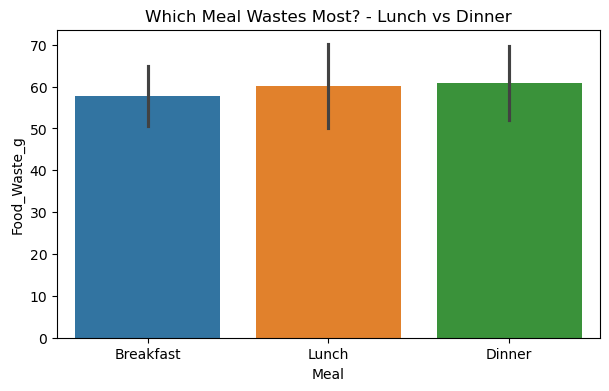

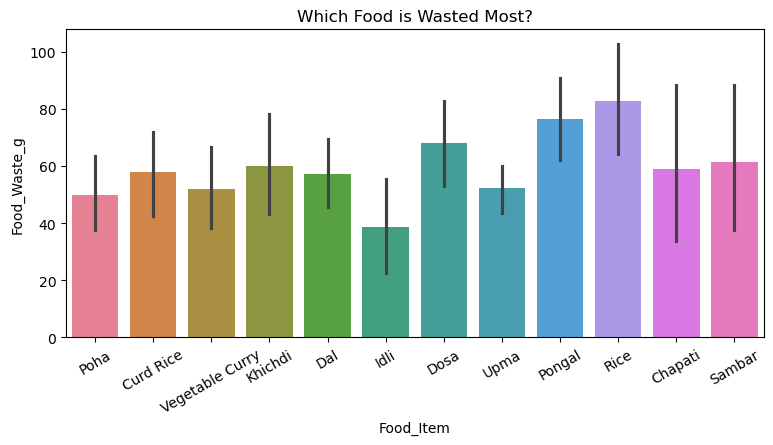

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,4))
sns.barplot(x='Meal', y='Food_Waste_g', data=df, hue='Meal', legend=False)
plt.title('Which Meal Wastes Most? - Lunch vs Dinner')
plt.show()

plt.figure(figsize=(9,4))
sns.barplot(x='Food_Item', y='Food_Waste_g', data=df, hue='Food_Item', legend=False)
plt.xticks(rotation=30)
plt.title('Which Food is Wasted Most?')
plt.show()

In [22]:
import sqlite3
conn = sqlite3.connect('pg_tracker.db')
df.to_sql('food_waste', conn, if_exists='replace', index=False)
print("Saved to SQL Successfully")

Saved to SQL Successfully


In [23]:
import sqlite3
conn = sqlite3.connect('pg_tracker.db')
print(pd.read_sql("SELECT * FROM food_waste LIMIT 5", conn))

  Student_ID        Date       Meal        Food_Item  Food_Served_g  \
0      PG121  2026-10-01  Breakfast             Poha            294   
1      PG145  2026-10-01      Lunch        Curd Rice            372   
2      PG055  2026-10-02     Dinner  Vegetable Curry            281   
3      PG056  2026-10-02     Dinner          Khichdi            262   
4      PG072  2026-10-02     Dinner  Vegetable Curry            300   

   Food_Consumed_g  Food_Waste_g  Waste_Percent  
0              236            58          19.73  
1              291            81          21.77  
2              212            69          24.56  
3              199            63          24.05  
4              290            10           3.33  
